# 11. Fit of γ_cal and of ρ: least squares against maximum likelihood

**Question.** γ_cal (Table 1) is a least-squares fit of the 2PCF. Would a
maximum-likelihood estimator give a better exponent? How much does the amplitude ratio
ρ depend on the SP draw?

**Data.** SP fractals and SP mixtures of known γ, then the nine datasets.
**Outputs.** `out/11_fit_validation.csv`, `out/11_fit_datasets.csv`,
`out/11_rho_sensitivity.csv` (and `out/11_cache/` for the curves). The cells reload
these files unless `FORCE = True`.
**Paper.** Sec. 3.2 (fit of γ_cal) and Limitations (ρ).
**Code.** `src/powerlaw_fits.py`, `src/calibration.py`.

All the γ fits of a point set use the same pair counts, with the settings of the
calibration (20 logarithmic edges from the mean nearest-neighbour distance to r_max,
5 random catalogues of 7 000 points, 3 repetitions below 10⁴ nodes, 10 sub-samples of
10⁴ nodes above).

| key | estimator | what is fitted |
|---|---|---|
| `wls` | least squares on ξ, weighted by the inverse variance over the repetitions (paper) | ξ(r) = (r/r0)^(−γ), bins 1 to 18 |
| `ols_log` | unweighted least squares on log ξ against log r | same bins, ξ > 0 |
| `mle` | maximum likelihood, DD_i ~ Poisson(P_i N_pairs (1 + ξ_i)), P_i from the random pairs | same bins |
| `pk_r0` | `powerlaw` package on x = r_hi / d for the pairs d < r_hi = r0, γ = 3 − α | correlation dimension D2 = 2 − γ |
| `pk_rmax` | same, r_hi = r_max | same |

The `powerlaw` package fits probability distributions, not a correlation function.
It applies to the pair distances, whose density in 2D is ∝ d (1 + ξ(d)) ≈ d^(1−γ) when
ξ ≫ 1 and far from the border (Takens estimator of D2). Version 1.5 ignores `xmax` in
the normalisation of a continuous power law (on a power law of exponent 2.2 truncated at
50 it returns 2.258 instead of 2.205), so the distances are only cut from above.
Running time about 40 minutes without the cache.

In [1]:
import sys, pickle, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent.parent
sys.path.insert(0, str(ROOT / "src"))

import synthesis_utils as su
import calibration as cal
import sp_helpers as sh
import powerlaw_fits as pf

OUT = ROOT / "out"
CACHE = OUT / "11_cache"
CACHE.mkdir(exist_ok=True)
FORCE = False          # True recomputes everything
N_REAL = 20            # SP realisations per configuration

METHODS = {
    "wls": "least squares, weighted (paper)",
    "ols_log": "least squares, log-log",
    "mle": "Poisson MLE on DD",
    "pk_r0": "powerlaw, d < r0",
    "pk_rmax": "powerlaw, d < r_max",
}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})


def all_fits(xy, gdf_edge, rmax, rng):
    # The five estimates of gamma on one point set, from the same pair counts.
    edges, reps, same = pf.calib_counts(xy, gdf_edge, rmax, rng)
    xis = [pf.ls_xi(c) for c in reps]
    g_w, e_w, r0_w = pf.fit_wls(edges, xis)
    g_o, _, r0_o = pf.fit_ols_log(edges, xis)
    g_m, e_m, r0_m = pf.fit_poisson_mle(edges, reps, same)
    if len(xy) <= 10_000:
        pts = [xy]
    else:
        pts = [xy[rng.choice(len(xy), 10_000, replace=False)] for _ in range(3)]
    r_hi = r0_w if (np.isfinite(r0_w) and edges[1] < r0_w < rmax) else edges[5]
    g_p, e_p, R_p, p_p, n_p = pf.fit_powerlaw_pkg(pts, r_hi)
    g_q, e_q, _, _, n_q = pf.fit_powerlaw_pkg(pts, rmax, compare=False)
    row = dict(N=len(xy), wls=g_w, wls_err=e_w, r0_wls=r0_w, ols_log=g_o,
               mle=g_m, mle_err=e_m, r0_mle=r0_m,
               pk_r0=g_p, pk_r0_err=e_p, pk_r0_R=R_p, pk_r0_p=p_p, pk_r0_pairs=n_p,
               pk_rmax=g_q, pk_rmax_err=e_q, pk_rmax_pairs=n_q)
    curve = dict(edges=edges, xi=np.mean(xis, axis=0), xi_sd=np.std(xis, axis=0),
                 r0_wls=r0_w, r0_mle=r0_m, wls=g_w, mle=g_m, ols_log=g_o, r0_ols=r0_o)
    return row, curve

## 1. Validation on SP point sets of known γ

Two configurations of Table 1 (Belgian cities, η = 2, and RTE substations, η = 6),
with γ = γ_cal as input. For each one, `N_REAL` fractals (`build_sp_model`, seeded) and
the mixture with the final SP fraction of Table 1 (0.41 and 0.29). The input γ is the
reference. Eq. (1) only holds on average over realisations and for r_min < r < R, so
the fractal itself departs from it by a few hundredths to a few tenths, the same for
every estimator.

In [2]:
CONF = {"Belgium Cities": 333 / 815, "RTE France": 1426 / 4932}
f_val, f_cur = OUT / "11_fit_validation.csv", CACHE / "validation_curves.pkl"

if f_val.exists() and f_cur.exists() and not FORCE:
    val = pd.read_csv(f_val)
    curves_val = pickle.load(open(f_cur, "rb"))
else:
    rows, curves_val = [], {}
    for name, f_sp in CONF.items():
        ds = su.DATASETS[name]
        gdf_edge, R_ref = cal.load_territory(ds)
        t0 = time.time()
        for i in range(N_REAL):
            np.random.seed(1000 + i)                 # SP draw (global stream)
            rng = np.random.default_rng(2000 + i)    # catalogues and thinning
            pos_sp, L, lamb = sh.build_sp_model(ds["m_star"], ds["eta"],
                                                ds["gamma_data"], R_ref,
                                                gdf_edge, ds["crs"])
            n_sp = min(int(round(f_sp * ds["N"])), len(pos_sp))
            sp_part = pos_sp[rng.choice(len(pos_sp), n_sp, replace=False)]
            mix = np.vstack([sp_part, pf.random_in(gdf_edge, ds["N"] - n_sp, rng)])
            for kind, xy in (("fractal", pos_sp), ("mixture", mix)):
                row, cur = all_fits(xy, gdf_edge, ds["rmax"], rng)
                rows.append(dict(dataset=name, kind=kind, real=i, L=L,
                                 gamma_true=ds["gamma_data"], **row))
                curves_val[(name, kind, i)] = cur
        print(f"{name}: {N_REAL} realisations in {time.time() - t0:.0f} s")
    val = pd.DataFrame(rows)
    val.to_csv(f_val, index=False)
    pickle.dump(curves_val, open(f_cur, "wb"))

summ = []
for (name, kind), g in val.groupby(["dataset", "kind"], sort=False):
    for m in METHODS:
        d = g[m] - g["gamma_true"]
        summ.append(dict(dataset=name, kind=kind, method=m, bias=d.mean(),
                         sd=d.std(), rmse=np.sqrt((d ** 2).mean())))
summ = pd.DataFrame(summ)
summ.pivot_table(index=["dataset", "kind"], columns="method",
                 values=["bias", "sd"], sort=False)[["bias", "sd"]].round(3)

'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.


'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.


  L=10: 673 inside < 718, trying L=11


  L=10: 366 inside < 718, trying L=11


'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.


'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.


... (20 outputs left out)

'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.


'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.


RTE France: 20 realisations in 114 s


bias                                   sd          \
method                    wls ols_log    mle  pk_r0 pk_rmax    wls ols_log   
dataset        kind                                                          
Belgium Cities fractal  0.054   0.288  0.568  0.273   0.609  0.059   0.149   
               mixture  0.373   0.484  0.475 -0.162   0.291  0.186   0.285   
RTE France     fractal  0.002   0.077  0.139 -0.175   0.107  0.055   0.064   
               mixture -0.034   0.181  0.147 -0.234  -0.533  0.105   0.217   

                                              
method                    mle  pk_r0 pk_rmax  
dataset        kind                           
Belgium Cities fractal  0.078  0.181   0.048  
               mixture  0.161  0.090   0.040  
RTE France     fractal  0.168  0.078   0.143  
               mixture  0.307  0.061   0.055

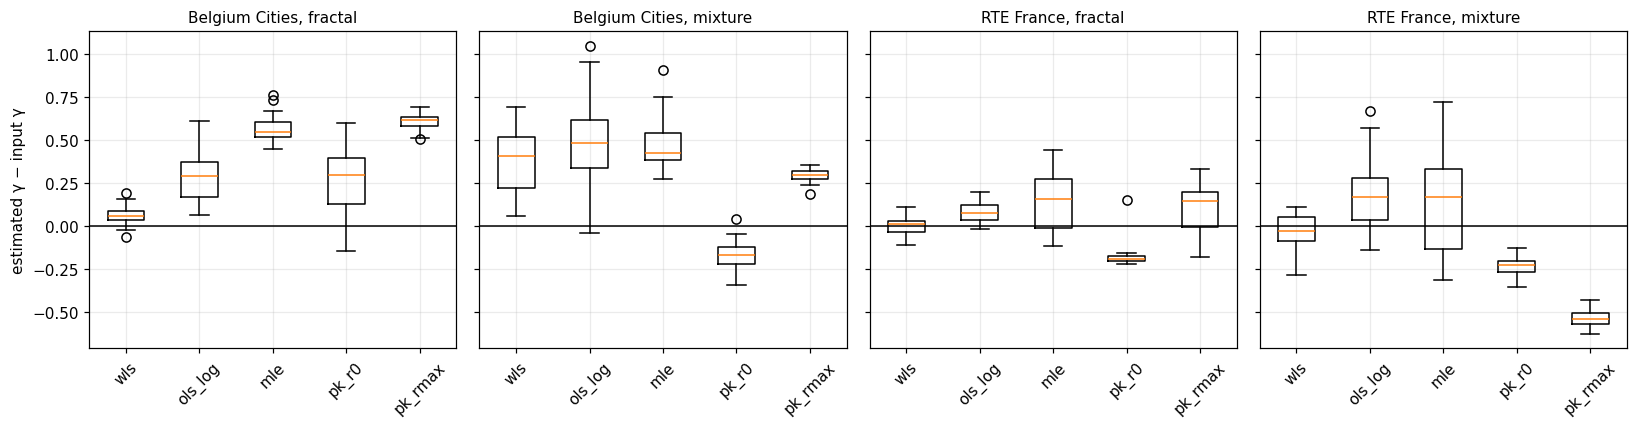

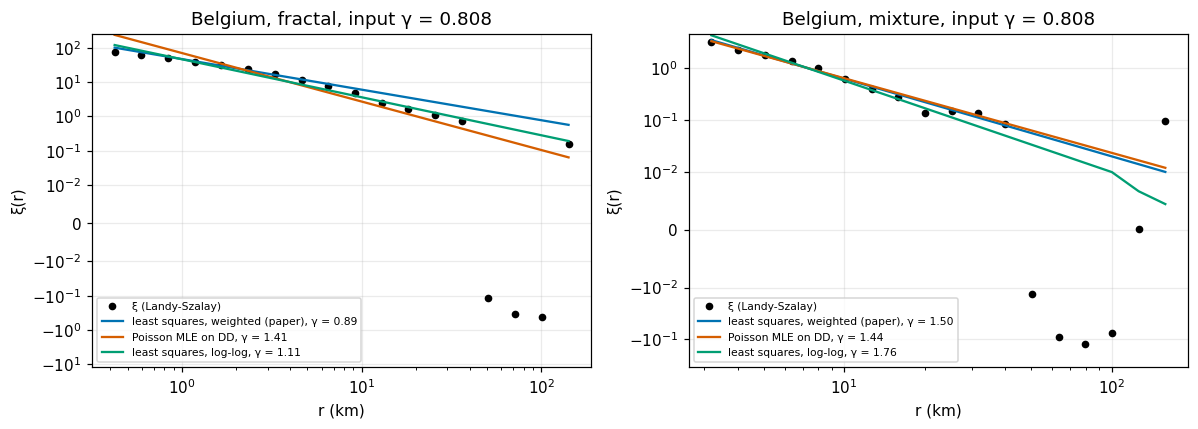

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True)
for ax, ((name, kind), g) in zip(axes, val.groupby(["dataset", "kind"], sort=False)):
    data = [g[m] - g["gamma_true"] for m in METHODS]
    ax.boxplot(data, labels=list(METHODS), showfliers=True)
    ax.axhline(0, color="k", lw=1)
    ax.set_title(f"{name}, {kind}", fontsize=10)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("estimated γ − input γ")
plt.tight_layout(); plt.show()

# 2PCF of one fractal and one mixture (Belgium) with the WLS and MLE fits
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kind in zip(axes, ("fractal", "mixture")):
    c = curves_val[("Belgium Cities", kind, 0)]
    r = c["edges"][pf.A:pf.B]; xi = c["xi"][pf.A:pf.B]
    ax.plot(r / 1e3, xi, "o", color="k", ms=4, label="ξ (Landy-Szalay)")
    for key, col in (("wls", "#0072B2"), ("mle", "#D55E00"), ("ols_log", "#009E73")):
        r0 = c["r0_ols"] if key == "ols_log" else c[f"r0_{key}"]
        ax.plot(r / 1e3, pf.pl(r, c[key], r0), "-", color=col,
                label=f"{METHODS[key]}, γ = {c[key]:.2f}")
    ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1e-2)
    ax.set_xlabel("r (km)"); ax.set_ylabel("ξ(r)")
    ax.set_title(f"Belgium, {kind}, input γ = {su.DATASETS['Belgium Cities']['gamma_data']}")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

- On the fractals, the fit of the paper (`wls`) is the only one without bias: +0.05 ± 0.06
  (Belgium) and 0.00 ± 0.06 (RTE). The maximum likelihood overestimates γ by 0.57 and
  0.14, the log-log fit by 0.29 and 0.08, and the `powerlaw` package is off by 0.1 to 0.6
  depending on the cut.
- On the RTE mixture (4 932 nodes), `wls` stays the best, −0.03 ± 0.10 (RMSE 0.11 against
  0.24 or more for the others).
- On the Belgian mixture (815 nodes, 333 from the fractal), no estimator recovers the input
  γ within 0.15. `wls` gives +0.37 ± 0.19, the maximum likelihood +0.48, and `pk_r0`
  −0.16 ± 0.09. With so few nodes the limit is the sample, not the fit.
- The maximum likelihood fails for a simple reason. Its weights grow with the number of
  pairs, and most pairs lie at large r, where ξ bends down to zero (finite fractal, border).
  The fit follows this drop. The weights of `wls` favour the small-r bins, where the power
  law holds. A single power law is not the right model over the whole window, and the
  likelihood makes this worse.
- The `powerlaw` package measures the distribution of the pair distances. It is a power law
  only where ξ ≫ 1 and far from the border, and the factor 1 + ξ flattens it elsewhere.

## 2. The nine datasets

Same estimators on the data, with the calibration settings. `gamma_cal_paper` is the
value of Table 1. The random catalogues are seeded here, so `wls` differs slightly from
Table 1 (unseeded original runs).

In [4]:
f_dat, f_dcur = OUT / "11_fit_datasets.csv", CACHE / "dataset_curves.pkl"
if f_dat.exists() and f_dcur.exists() and not FORCE:
    dat = pd.read_csv(f_dat)
    curves_dat = pickle.load(open(f_dcur, "rb"))
else:
    rows, curves_dat = [], {}
    for name, ds in su.DATASETS.items():
        if not (ds["path_csv"].exists() and ds["path_border"].exists()):
            print(f"{name}: files missing, skipped")
            continue
        t0 = time.time()
        rng = np.random.default_rng(7)
        gdf_edge, R_ref = cal.load_territory(ds)
        _, xy, _ = cal.load_points(ds, gdf_edge)
        row, cur = all_fits(xy, gdf_edge, ds["rmax"], rng)
        rows.append(dict(dataset=name, gamma_cal_paper=ds["gamma_data"], **row))
        curves_dat[name] = cur
        print(f"{name}: N = {len(xy):,}, {time.time() - t0:.0f} s")
    dat = pd.DataFrame(rows)
    dat.to_csv(f_dat, index=False)
    pickle.dump(curves_dat, open(f_dcur, "wb"))

cols = ["dataset", "N", "gamma_cal_paper"] + list(METHODS) + ["pk_r0_R", "pk_r0_p"]
dat[cols].round(3)

Austria Cities: N = 2,253, 4 s


Belgium Cities: N = 815, 3 s


'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.


RTE France: N = 4,932, 3 s


Gares France: N = 3,470, 3 s


ENEDIS France: N = 912,982, 12 s


... (3 outputs left out)

'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.


Germany Stops: N = 660,298, 13 s


Swiss Stops: N = 93,288, 38 s


,dataset,N,gamma_cal_paper,wls,ols_log,mle,pk_r0,pk_rmax,pk_r0_R,pk_r0_p
0,Austria Cities,2253,0.789,0.743,0.799,1.512,-0.018,0.859,-4.488,0.000
1,Belgium Cities,815,0.808,0.838,0.769,1.182,-0.064,1.011,-4.717,0.000
2,RTE France,4932,0.931,0.883,1.005,1.826,0.754,0.416,4.802,0.000
3,Gares France,3470,0.643,0.683,1.047,1.512,0.640,0.634,-31.446,0.000
4,ENEDIS France,912982,0.954,0.923,1.022,1.675,0.306,0.310,-4.011,0.000
5,France Communes,34269,0.254,0.252,0.261,0.808,-0.104,0.226,-16.182,0.000
6,France Routes,897965,0.525,0.522,0.580,1.655,0.214,0.236,1.299,0.194
7,Germany Stops,660298,0.612,0.603,0.669,1.164,0.470,0.332,8.197,0.000
8,Swiss Stops,93288,0.873,0.851,0.970,1.564,0.568,0.685,25.547,0.000


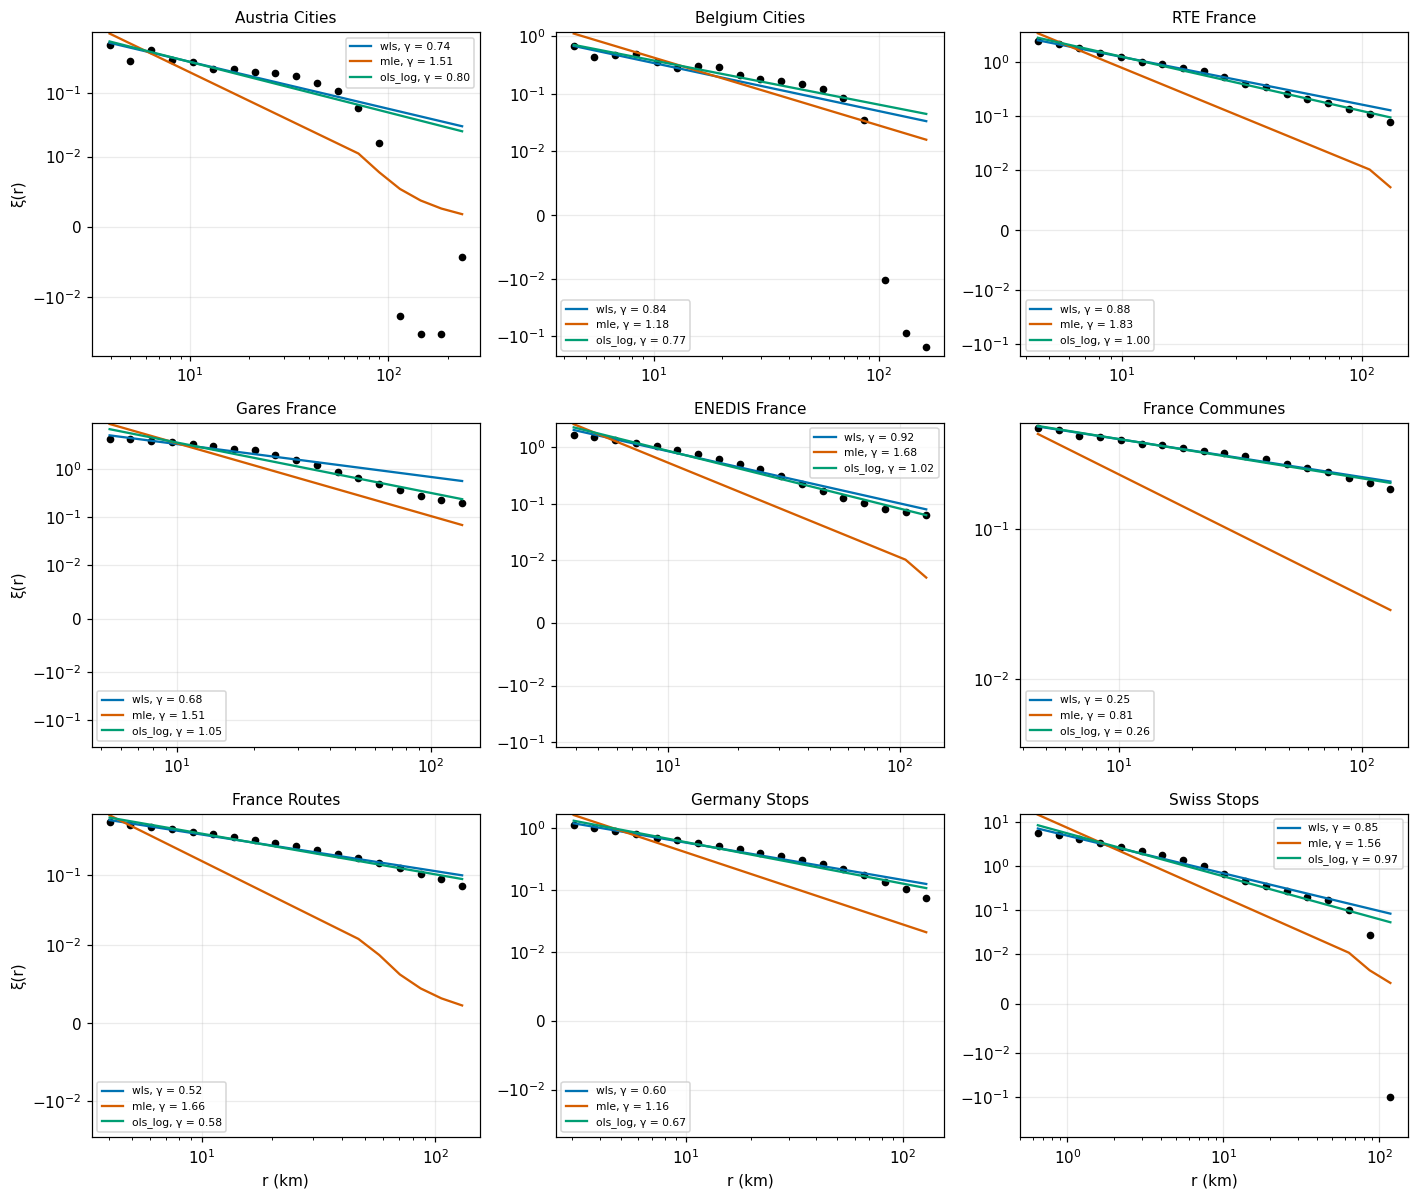

In [5]:
names = list(curves_dat)
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for ax, name in zip(axes.ravel(), names):
    c = curves_dat[name]
    r = c["edges"][pf.A:pf.B]; xi = c["xi"][pf.A:pf.B]
    ax.plot(r / 1e3, xi, "o", color="k", ms=4)
    for key, col in (("wls", "#0072B2"), ("mle", "#D55E00"), ("ols_log", "#009E73")):
        r0 = c["r0_ols"] if key == "ols_log" else c[f"r0_{key}"]
        ax.plot(r / 1e3, pf.pl(r, c[key], r0), "-", color=col,
                label=f"{key}, γ = {c[key]:.2f}")
    ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1e-2)
    ax.set_title(name, fontsize=10); ax.legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("r (km)")
for ax in axes[:, 0]:
    ax.set_ylabel("ξ(r)")
plt.tight_layout(); plt.show()

- `wls` gives back Table 1 within 0.05 on every dataset (the catalogues are seeded here).
- The maximum likelihood gives γ between 0.81 and 1.83, 0.4 to 0.9 above γ_cal. Such
  values do not describe the slope of the data at small r (figure above) and would give an
  unrealistic λ = η^(1/(2−γ)).
- The log-log fit is within 0.1 of γ_cal on eight datasets, and 0.40 above on the railway
  stations.
- The `powerlaw` package gives −0.10 to 0.75 with the cut at r0, and the lognormal
  distribution is preferred to the power law (R < 0, p < 0.01) on five datasets.

## 3. Sensitivity of ρ to the SP draw

Belgian cities, ten fractals (seeds 0 to 9) with m*, η and γ of Table 1, and the data
2PCF of `calibration.data_2pcf`. ρ is the mean of ξ_data / ξ_SP over the bins where
ξ_SP > 0 (step 4 of Sec. 3.1). The median of the same ratios is shown for comparison and
is not used. The catalogues of `calibration.py` are not seeded, so the values change
slightly from one run to the next.

In [6]:
f_rho = OUT / "11_rho_sensitivity.csv"
if f_rho.exists() and not FORCE:
    rho_tab = pd.read_csv(f_rho)
else:
    ds = su.DATASETS["Belgium Cities"]
    gdf_edge, R_ref = cal.load_territory(ds)
    gdf_projected, coords, marks = cal.load_points(ds, gdf_edge)
    r_edges, l_xi = cal.data_2pcf(gdf_projected, gdf_edge, ds["crs"], ds["rmax"])
    xi_data = sh._xi_mean(r_edges, l_xi)
    rows = []
    for s in range(10):
        np.random.seed(s)
        pos_s, L_s, _ = sh.build_sp_model(ds["m_star"], ds["eta"], ds["gamma_data"],
                                          R_ref, gdf_edge, ds["crs"])
        r_s, l_s = cal.sp_2pcf(pos_s, gdf_edge, ds["crs"], ds["rmax"])
        x_s = sh._xi_mean(r_s, l_s)
        al = sh._align(r_s[:len(x_s)], x_s, r_edges)
        m = al[1:] > 1e-6
        ratio = xi_data[1:][m] / al[1:][m]
        rows.append(dict(seed=s, L=L_s, m_SP=len(pos_s), mean_ratio=ratio.mean(),
                         median_ratio=np.median(ratio), min_ratio=ratio.min()))
    rho_tab = pd.DataFrame(rows)
    rho_tab.to_csv(f_rho, index=False)

print(rho_tab.round(4).to_string(index=False))
print(f"\nmean ratio:   {rho_tab.mean_ratio.min():.3f} to {rho_tab.mean_ratio.max():.3f}"
      f"  ({rho_tab.mean_ratio.mean():.3f} ± {rho_tab.mean_ratio.std():.3f})")
print(f"median ratio: {rho_tab.median_ratio.min():.3f} to {rho_tab.median_ratio.max():.3f}")

  L=10: 690 inside < 718, trying L=11


  L=10: 584 inside < 718, trying L=11


  L=10: 716 inside < 718, trying L=11


  L=10: 631 inside < 718, trying L=11


  L=10: 446 inside < 718, trying L=11


 seed  L  m_SP  mean_ratio  median_ratio  min_ratio
    0 11  2046      0.1329        0.0724     0.0350
    1 10   890      0.4586        0.1107     0.0335
    2 10  1024     -0.0273        0.0577    -1.4090
    3 11  1913      0.1031        0.0654    -1.1030
    4 10   763      0.3634        0.0650    -0.2216
    5 10   960      0.2208        0.0797    -0.5830
    6 11  1024      2.3106        0.0800     0.0351
    7 11  2048      0.0784        0.0768    -0.3656
    8 11  1467      0.1663        0.0894     0.0448
    9 10   794      0.0802        0.0945    -0.5861

mean ratio:   -0.027 to 2.311  (0.389 ± 0.690)
median ratio: 0.058 to 0.111


- The mean ratio ρ goes from −0.03 to 2.31 over the ten draws, and two draws fall outside
  [0, 1] (they are clipped to 10⁻⁴ and 1 by the calibration). The former run of the same
  test gave −0.02 to 0.28.
- The median ratio stays between 0.058 and 0.111.
- ρ is the fragile step of the calibration, and the median is a more stable estimator.

## Results

1. The weighted least-squares fit of the paper is kept. It is the only estimator without
   bias on SP fractals of known γ, and the maximum likelihood on the pair counts
   overestimates γ by 0.14 to 0.57 on the fractals and by 0.4 to 0.9 on the data.
2. The `powerlaw` package does not apply to a correlation function. On the pair distances
   it is biased (1 + ξ instead of ξ, no border correction), and version 1.5 ignores `xmax`.
3. With 815 nodes (Belgian mixture) no estimator recovers γ within 0.15.
4. ρ depends strongly on the SP draw (mean ratio −0.03 to 2.31), its median much less
   (0.06 to 0.11).